# KOI 2700b: Presentation Notebook

### Imports

In [1]:
import numpy as np
import warnings
warnings.filterwarnings("ignore")
import lightkurve as lk
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import astropy.io

### Query data from Kepler

In [2]:
search_result = lk.search_lightcurve('KIC 8639908', author='Kepler', cadence="long")
search_result

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,Kepler Quarter 01,2009,Kepler,1800,kplr008639908,0.0
1,Kepler Quarter 02,2009,Kepler,1800,kplr008639908,0.0
2,Kepler Quarter 03,2009,Kepler,1800,kplr008639908,0.0
3,Kepler Quarter 04,2010,Kepler,1800,kplr008639908,0.0
4,Kepler Quarter 05,2010,Kepler,1800,kplr008639908,0.0
5,Kepler Quarter 06,2010,Kepler,1800,kplr008639908,0.0
6,Kepler Quarter 07,2010,Kepler,1800,kplr008639908,0.0
7,Kepler Quarter 08,2011,Kepler,1800,kplr008639908,0.0
8,Kepler Quarter 09,2011,Kepler,1800,kplr008639908,0.0


In [3]:
# First 16 quarters as used in the paper
lc_all = search_result.download_all()[0:16]

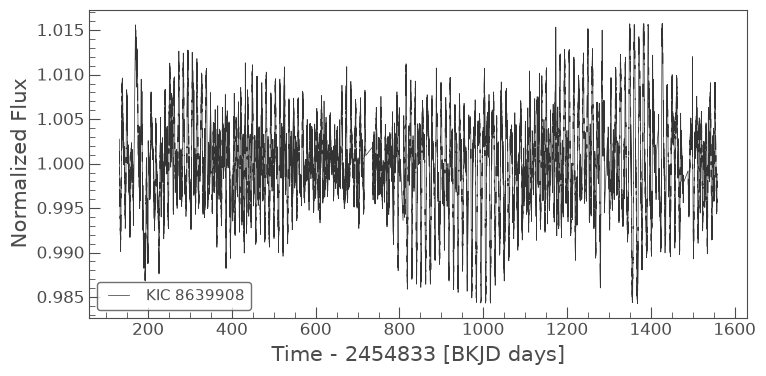

In [8]:
# Clipped to 3 sigma
combined_lc = lc_all.stitch().remove_outliers(sigma=3.0)

combined_lc.plot()
plt.show()

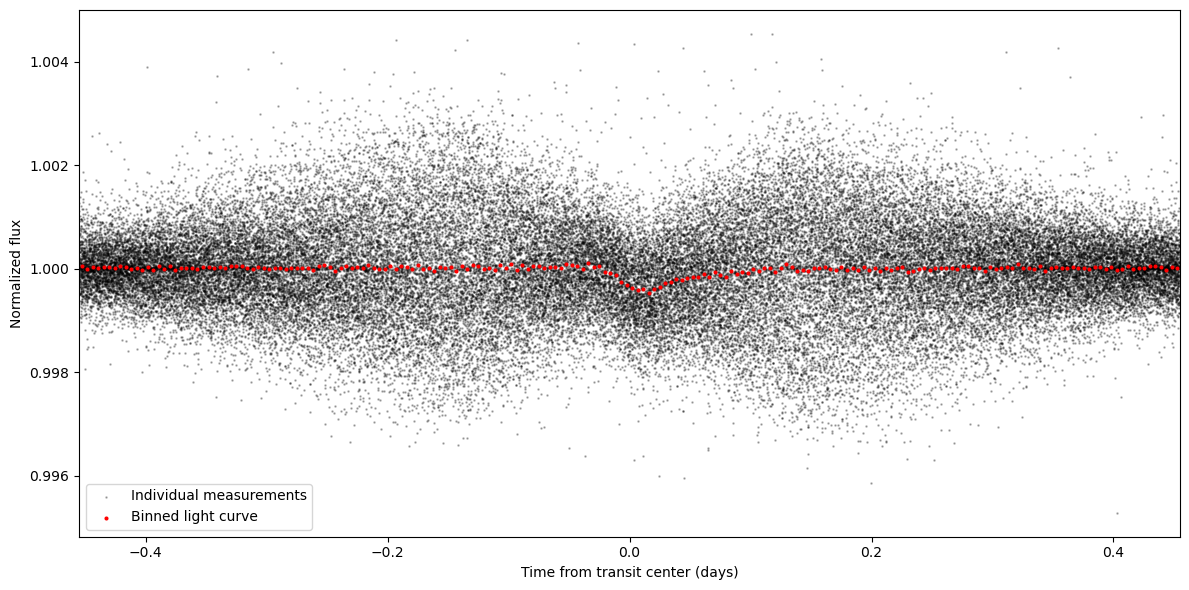

In [4]:
# Process each quarter independently
period = 0.910022 # days
transit_time = 67.358 # BKJD
transit_duration = 0.25 # days
processed_lcs = []

for lc in lc_all:
    lc = lc.remove_nans()

    # Normalize each quarter separately
    lc = lc.normalize()

    # Check the time convention before relying on transit_time
    # Kepler long-cadence light curves commonly use BKJD.
    transit_mask = lc.create_transit_mask(
        period=period,
        transit_time=transit_time,
        duration=transit_duration
    )

    flat_lc = lc.flatten(
        window_length=401,
        mask=transit_mask
    )

    processed_lcs.append(flat_lc)

# Combine the processed quarters
combined_lc = lk.LightCurveCollection(processed_lcs).stitch().remove_outliers(sigma=5.0)

# Fold on the planet's orbital period
folded = combined_lc.fold(
period=period,
epoch_time=transit_time
)

# Bin into 200 bins per orbit: approximately 6.55 minutes per bin
bin_size_days = period / 200
binned = folded.bin(time_bin_size=bin_size_days)

# Plot the folded light curve
fig, ax = plt.subplots(figsize=(12, 6))

folded.scatter(
    ax=ax,
    color="black",
    s=3,
    alpha=0.25,
    label="Individual measurements"
)

binned.scatter(
    ax=ax,
    color="red",
    s=15,
    label="Binned light curve"
)

ax.set_xlim(-period/2, period/2)
ax.set_xlabel("Time from transit center (days)")
ax.set_ylabel("Normalized flux")
ax.legend()
plt.tight_layout()
plt.show()